# Predicción de enfermedad cardíaca mediante aprendizaje automático

**Proyecto de Minería de Datos — Segundo informe de avance**

Este notebook analiza `patient_dataset.csv`, revisa la calidad de los datos, realiza análisis exploratorio y compara modelos de clasificación. Los resultados se calculan a partir del archivo CSV disponible al ejecutar el notebook; no se deben asumir resultados antes de ejecutarlo.

**Importante:** este análisis es académico y experimental. No sirve para diagnosticar pacientes ni para tomar decisiones clínicas.

## 1. Configuración e importación de librerías

Ejecuta esta celda para importar las librerías necesarias. Si alguna no está instalada, instala el paquete correspondiente en tu entorno de Jupyter.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.base import clone

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 2. Carga del dataset

Coloca `patient_dataset.csv` en la misma carpeta que este notebook. Si el archivo está en otra ubicación, modifica `DATA_PATH`.

In [2]:
DATA_PATH = "patient_dataset.csv"

df = pd.read_csv(DATA_PATH)
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
display(df.head())

Filas: 6,000 | Columnas: 16


,age,gender,chest_pain_type,blood_pressure,cholesterol,max_heart_rate,exercise_angina,plasma_glucose,skin_thickness,insulin,bmi,diabetes_pedigree,hypertension,heart_disease,residence_type,smoking_status
0,24,1.0,4,250,139,212,0,108.0,33.0,109.0,37.999303,0.480277,1,1,Urban,Smoker
1,29,0.0,4,132,187,147,0,202.0,42.0,NaN,25.588346,0.283986,1,1,Urban,Unknown
2,46,0.0,3,271,185,193,0,149.0,43.0,102.0,37.892029,2.472309,1,0,Rural,Non-Smoker
3,73,NaN,2,102,200,125,0,105.0,77.0,165.0,18.660241,1.472052,0,1,Rural,Smoker
4,49,1.0,3,91,163,192,0,162.0,31.0,170.0,12.767980,0.537627,1,1,Rural,Smoker


## 3. Estructura y calidad de los datos

Esta sección comprueba tipos, duplicados, valores faltantes y estadísticas descriptivas. No elimina filas automáticamente.

In [3]:
display(pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "faltantes": df.isna().sum(),
    "porcentaje_faltante": (df.isna().mean() * 100).round(2),
    "valores_unicos": df.nunique(dropna=True)
}).sort_values("faltantes", ascending=False))

print("Filas duplicadas:", df.duplicated().sum())
display(df.describe(include="all").T)

,tipo,faltantes,porcentaje_faltante,valores_unicos
skin_thickness,float64,614,10.23,81
plasma_glucose,float64,609,10.15,181
insulin,float64,568,9.47,101
gender,float64,472,7.87,2
residence_type,object,455,7.58,2
blood_pressure,int64,0,0.00,231
chest_pain_type,int64,0,0.00,4
age,int64,0,0.00,73
exercise_angina,int64,0,0.00,2
max_heart_rate,int64,0,0.00,151


Filas duplicadas: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,6000.0,NaN,NaN,NaN,53.657833,21.018382,18.0,36.0,53.0,72.0,90.0
gender,5528.0,NaN,NaN,NaN,0.497648,0.50004,0.0,0.0,0.0,1.0,1.0
chest_pain_type,6000.0,NaN,NaN,NaN,2.5185,1.124071,1.0,2.0,3.0,4.0,4.0
blood_pressure,6000.0,NaN,NaN,NaN,134.277167,48.303001,0.0,109.0,135.0,161.0,300.0
cholesterol,6000.0,NaN,NaN,NaN,209.844667,52.840432,120.0,164.0,210.0,257.0,300.0
max_heart_rate,6000.0,NaN,NaN,NaN,144.996,43.583318,70.0,108.0,144.0,183.0,220.0
exercise_angina,6000.0,NaN,NaN,NaN,0.503167,0.500032,0.0,0.0,1.0,1.0,1.0
plasma_glucose,5391.0,NaN,NaN,NaN,161.119644,52.434693,70.0,116.0,162.0,206.0,250.0
skin_thickness,5386.0,NaN,NaN,NaN,59.964723,23.26403,20.0,40.0,60.0,80.0,100.0
insulin,5432.0,NaN,NaN,NaN,129.601252,29.207479,80.0,105.0,129.0,155.0,180.0


## 4. Validación de la variable objetivo

Se espera una columna llamada `heart_disease` con valores 0 y 1. Si el CSV usa otro nombre o codificación, revisa el archivo y adapta el notebook explícitamente.

In [4]:
TARGET = "heart_disease"

if TARGET not in df.columns:
    raise ValueError(f"No se encontró la columna '{TARGET}'. Columnas disponibles: {list(df.columns)}")

print("Valores observados en la variable objetivo:")
display(df[TARGET].value_counts(dropna=False).rename_axis(TARGET).to_frame("cantidad"))

if df[TARGET].isna().any():
    raise ValueError("La variable objetivo contiene valores faltantes. Deben revisarse antes de entrenar.")

observed_targets = set(pd.Series(df[TARGET]).dropna().unique())
if not observed_targets.issubset({0, 1}):
    raise ValueError(f"Se esperaba una variable binaria codificada como 0/1; se encontraron: {observed_targets}")

df[TARGET] = df[TARGET].astype(int)

Valores observados en la variable objetivo:


,cantidad
heart_disease,
0,3011
1,2989


## 5. Análisis exploratorio de datos

### Distribución de la variable objetivo

,cantidad,porcentaje
heart_disease,,
0,3011,50.18
1,2989,49.82


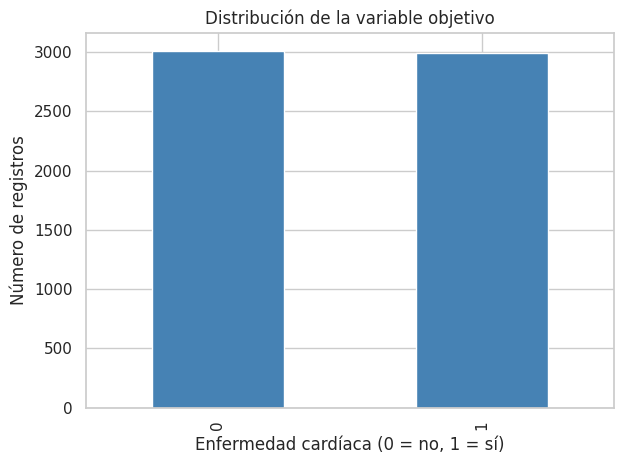

In [5]:
target_counts = df[TARGET].value_counts().sort_index()
display(pd.DataFrame({
    "cantidad": target_counts,
    "porcentaje": (target_counts / len(df) * 100).round(2)
}))

ax = target_counts.plot(kind="bar", color="steelblue")
ax.set_title("Distribución de la variable objetivo")
ax.set_xlabel("Enfermedad cardíaca (0 = no, 1 = sí)")
ax.set_ylabel("Número de registros")
plt.tight_layout()
plt.show()

### Variables numéricas y categóricas

Las columnas se detectan por tipo de dato. La clasificación automática puede requerir ajustes si algunas categorías están codificadas con números (por ejemplo, `chest_pain_type`).

In [6]:
X_all = df.drop(columns=[TARGET]).copy()

# Ajustar esta lista si el diccionario de datos indica que una columna numérica representa categorías.
categorical_candidates = [
    col for col in [
        "gender", "chest_pain_type", "residence_type", "smoking_status"
    ] if col in X_all.columns
]
# También tratar como categóricas las columnas de tipo object/category.
categorical_cols = sorted(set(
    categorical_candidates +
    X_all.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
))
numeric_cols = [c for c in X_all.columns if c not in categorical_cols]

print("Variables categóricas:", categorical_cols)
print("Variables numéricas:", numeric_cols)

Variables categóricas: ['chest_pain_type', 'gender', 'residence_type', 'smoking_status']
Variables numéricas: ['age', 'blood_pressure', 'cholesterol', 'max_heart_rate', 'exercise_angina', 'plasma_glucose', 'skin_thickness', 'insulin', 'bmi', 'diabetes_pedigree', 'hypertension']


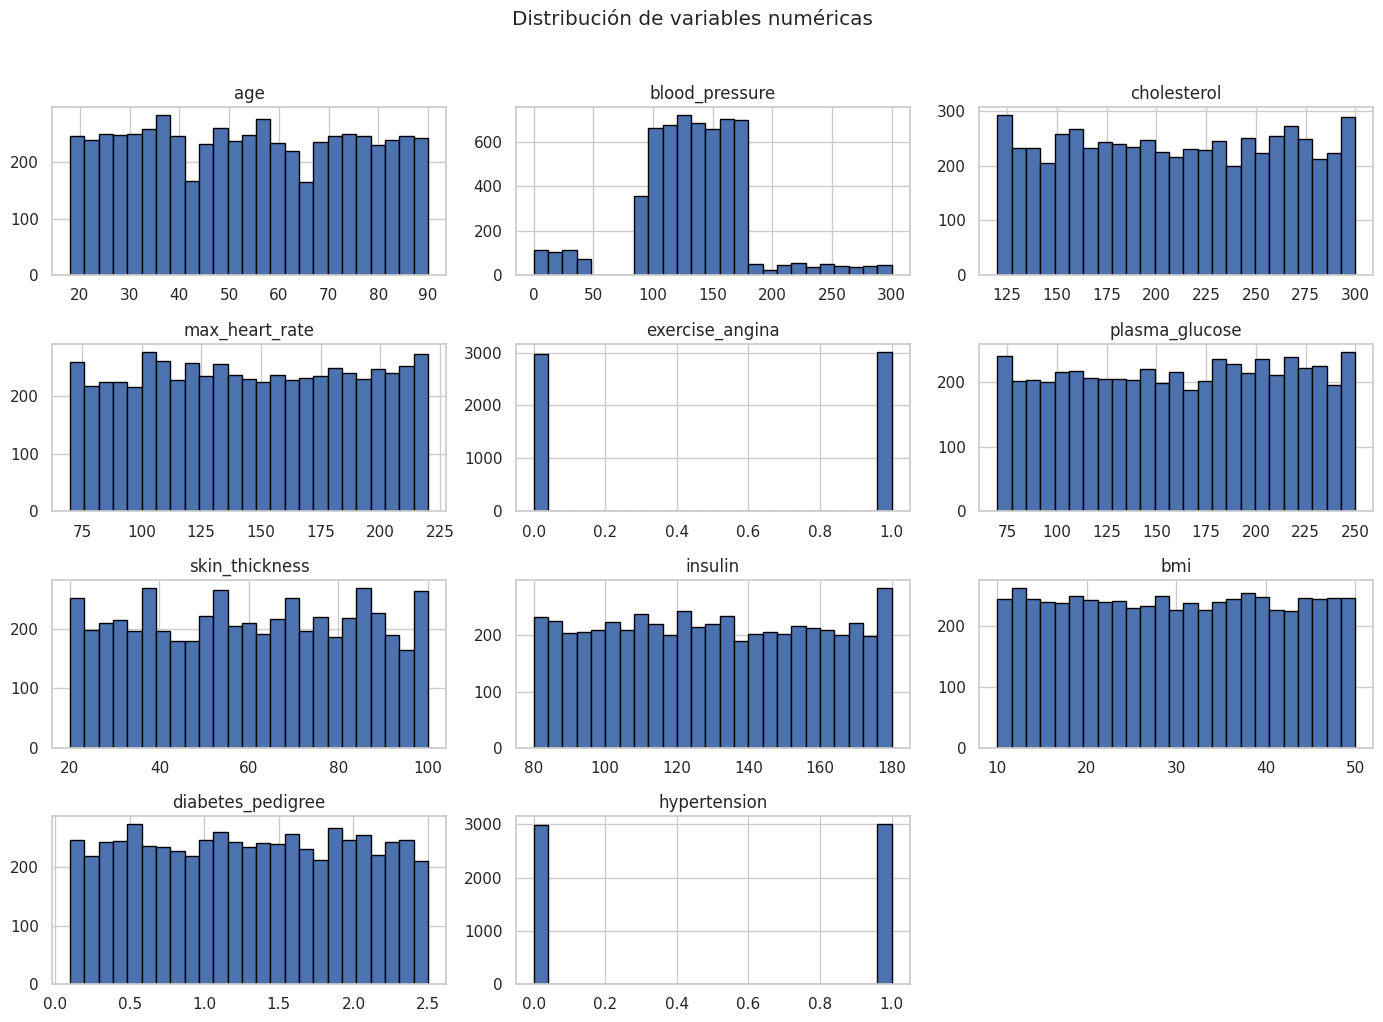

In [7]:
if numeric_cols:
    df[numeric_cols].hist(figsize=(14, 10), bins=25, edgecolor="black")
    plt.suptitle("Distribución de variables numéricas", y=1.02)
    plt.tight_layout()
    plt.show()

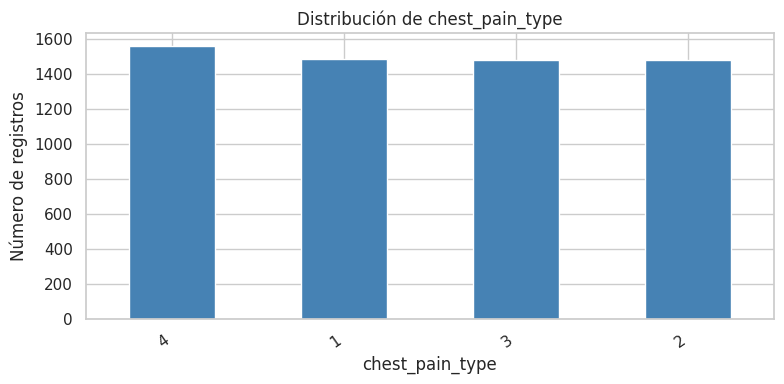

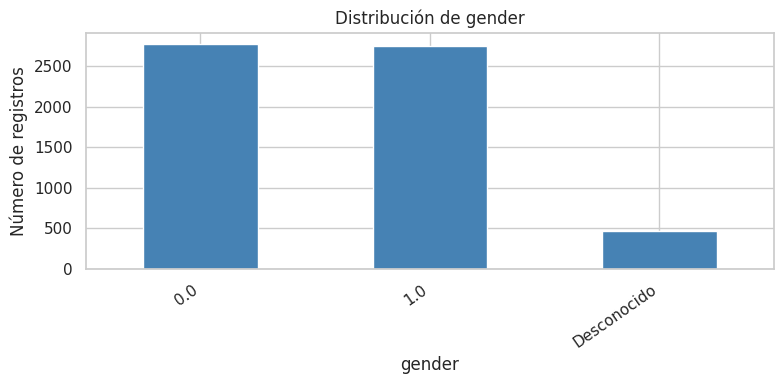

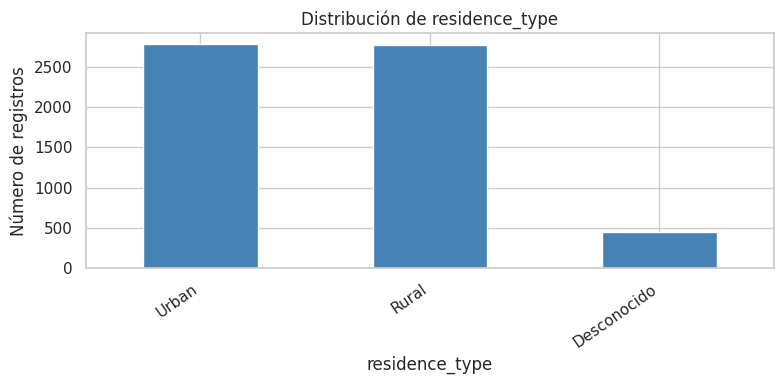

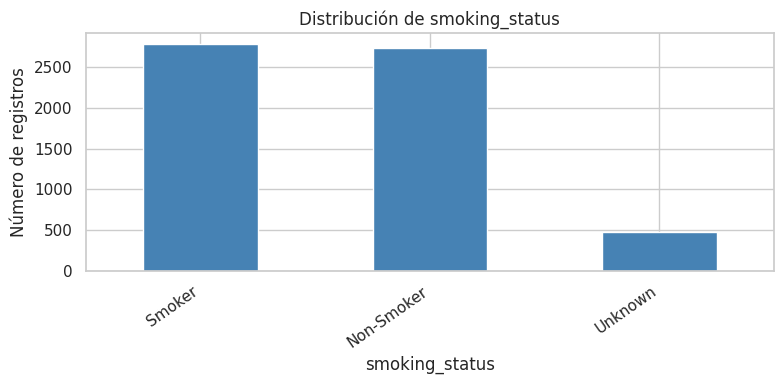

In [8]:
for col in categorical_cols:
    values = df[col].astype("string").fillna("Desconocido").value_counts()
    plt.figure(figsize=(8, 4))
    values.plot(kind="bar", color="steelblue")
    plt.title(f"Distribución de {col}")
    plt.xlabel(col)
    plt.ylabel("Número de registros")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

### Revisión de valores sospechosos en presión arterial

Los límites de 50 y 250 mm Hg se usan aquí como regla de revisión basada en el informe preliminar, no como una regla clínica universal. Verifica con el docente o el diccionario de datos antes de adoptar esta limpieza como definitiva.

Resumen de blood_pressure:


count    6000.000000
mean      134.277167
std        48.303001
min         0.000000
25%       109.000000
50%       135.000000
75%       161.000000
max       300.000000
Name: blood_pressure, dtype: float64

Valores fuera de [50, 250]: 576 (9.60%)


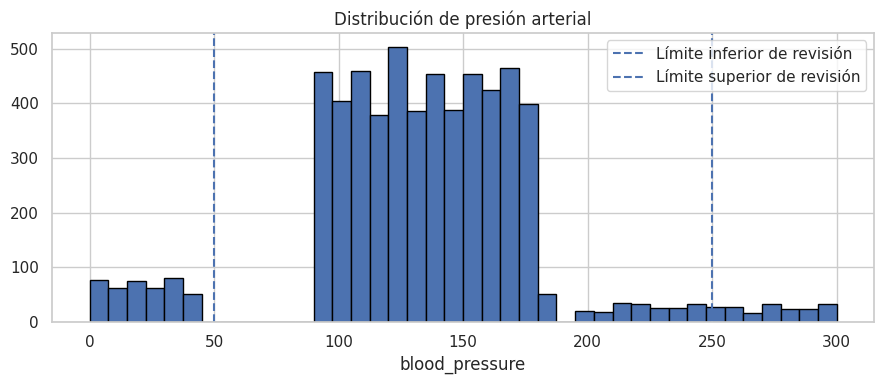

In [9]:
if "blood_pressure" in df.columns:
    bp = pd.to_numeric(df["blood_pressure"], errors="coerce")
    print("Resumen de blood_pressure:")
    display(bp.describe())
    suspicious_bp = bp.notna() & ~bp.between(50, 250)
    print(f"Valores fuera de [50, 250]: {int(suspicious_bp.sum())} ({suspicious_bp.mean()*100:.2f}%)")

    plt.figure(figsize=(9, 4))
    plt.hist(bp.dropna(), bins=40, edgecolor="black")
    plt.axvline(50, linestyle="--", label="Límite inferior de revisión")
    plt.axvline(250, linestyle="--", label="Límite superior de revisión")
    plt.title("Distribución de presión arterial")
    plt.xlabel("blood_pressure")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No existe la columna blood_pressure; se omite esta revisión.")

## 6. Preparación de datos sin fuga de información

Las transformaciones se ajustan dentro de los pipelines, usando únicamente los datos de entrenamiento. Para las variables numéricas se utiliza mediana y para las categóricas, la categoría más frecuente tras convertir los faltantes a `Desconocido`. Si se decide invalidar valores de presión arterial, la regla se aplica antes de la partición porque es una regla de calidad definida explícitamente; debe justificarse en el informe.

In [10]:
data_model = df.copy()

if "blood_pressure" in data_model.columns:
    data_model["blood_pressure"] = pd.to_numeric(data_model["blood_pressure"], errors="coerce")
    invalid_bp = ~data_model["blood_pressure"].between(50, 250) & data_model["blood_pressure"].notna()
    print("Valores de presión arterial convertidos a faltantes por regla [50, 250]:", int(invalid_bp.sum()))
    data_model.loc[invalid_bp, "blood_pressure"] = np.nan

X = data_model.drop(columns=[TARGET]).copy()
y = data_model[TARGET].astype(int).copy()

# Recalcular columnas después de la limpieza, manteniendo las categorías conocidas.
categorical_cols = sorted(set(
    [c for c in ["gender", "chest_pain_type", "residence_type", "smoking_status"] if c in X.columns] +
    X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
))
numeric_cols = [c for c in X.columns if c not in categorical_cols]

for col in categorical_cols:
    X[col] = X[col].astype("string").fillna("Desconocido").astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("Proporción de clase positiva — entrenamiento:", round(y_train.mean(), 3))
print("Proporción de clase positiva — prueba:", round(y_test.mean(), 3))

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
], remainder="drop")

Valores de presión arterial convertidos a faltantes por regla [50, 250]: 576
Entrenamiento: (4800, 15) | Prueba: (1200, 15)
Proporción de clase positiva — entrenamiento: 0.498
Proporción de clase positiva — prueba: 0.498


## 7. Entrenamiento y comparación de modelos

Se comparan regresión logística, árbol de decisión, Random Forest y un clasificador de referencia. Los parámetros son iniciales y no se ha realizado una búsqueda exhaustiva de hiperparámetros.

In [11]:
models = {
    "Referencia": DummyClassifier(strategy="prior"),
    "Regresión logística": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
    )
}

pipelines = {}
for name, model in models.items():
    # El escalamiento se aplica en el preprocesador común; los árboles pueden funcionar sin él,
    # aunque mantener un pipeline común facilita una comparación reproducible.
    pipelines[name] = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", model)
    ])

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    print(f"{name}: entrenado")

Referencia: entrenado
Regresión logística: entrenado
Árbol de decisión: entrenado


Random Forest: entrenado


## 8. Evaluación en el conjunto de prueba

El AUC se calcula a partir de probabilidades cuando el modelo las proporciona. Se muestran métricas de la clase positiva (`heart_disease = 1`) y especificidad.

In [12]:
def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return tn / (tn + fp) if (tn + fp) else np.nan

results = []
predictions = {}

for name, pipe in pipelines.items():
    y_pred = pipe.predict(X_test)
    predictions[name] = y_pred

    if hasattr(pipe, "predict_proba"):
        y_score = pipe.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, y_score)
    else:
        y_score = None
        auc = np.nan

    results.append({
        "Modelo": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "Especificidad": specificity_score(y_test, y_pred),
        "AUC-ROC": auc
    })

results_df = pd.DataFrame(results).set_index("Modelo").round(3)
display(results_df)

,Accuracy,Precision,Recall,F1,Especificidad,AUC-ROC
Modelo,,,,,,
Referencia,0.502,0.000,0.000,0.000,1.000,0.500
Regresión logística,0.489,0.486,0.441,0.463,0.537,0.476
Árbol de decisión,0.500,0.491,0.095,0.160,0.902,0.497
Random Forest,0.506,0.504,0.478,0.491,0.533,0.500


In [13]:
for name, pipe in pipelines.items():
    print("\n" + "=" * 70)
    print(name)
    print(classification_report(y_test, predictions[name], labels=[0, 1],
                                target_names=["Sin enfermedad (0)", "Con enfermedad (1)"],
                                zero_division=0))


Referencia
                    precision    recall  f1-score   support

Sin enfermedad (0)       0.50      1.00      0.67       602
Con enfermedad (1)       0.00      0.00      0.00       598

          accuracy                           0.50      1200
         macro avg       0.25      0.50      0.33      1200
      weighted avg       0.25      0.50      0.34      1200


Regresión logística
                    precision    recall  f1-score   support

Sin enfermedad (0)       0.49      0.54      0.51       602
Con enfermedad (1)       0.49      0.44      0.46       598

          accuracy                           0.49      1200
         macro avg       0.49      0.49      0.49      1200
      weighted avg       0.49      0.49      0.49      1200


Árbol de decisión
                    precision    recall  f1-score   support

Sin enfermedad (0)       0.50      0.90      0.64       602
Con enfermedad (1)       0.49      0.10      0.16       598

          accuracy                      

## 9. Matrices de confusión y curvas ROC

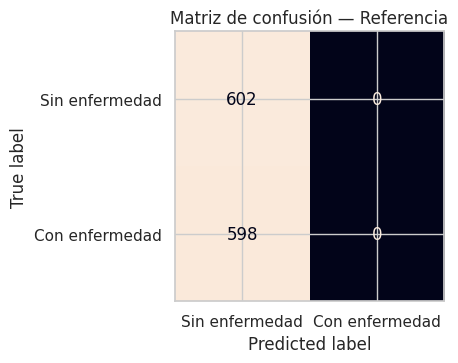

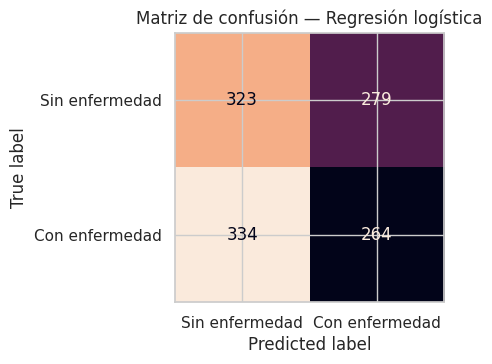

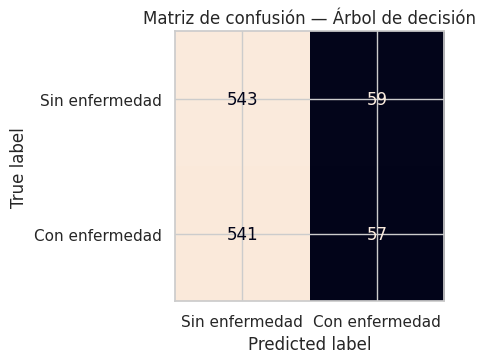

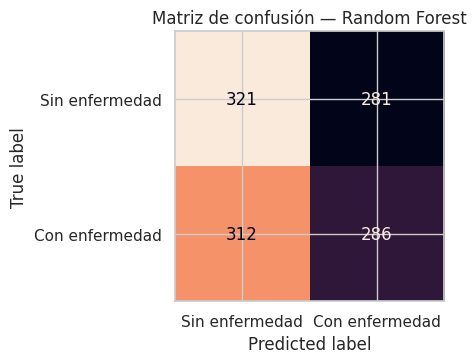

In [14]:
for name, pipe in pipelines.items():
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[name], labels=[0, 1],
        display_labels=["Sin enfermedad", "Con enfermedad"],
        cmap=None, colorbar=False, ax=ax
    )
    ax.set_title(f"Matriz de confusión — {name}")
    plt.tight_layout()
    plt.show()

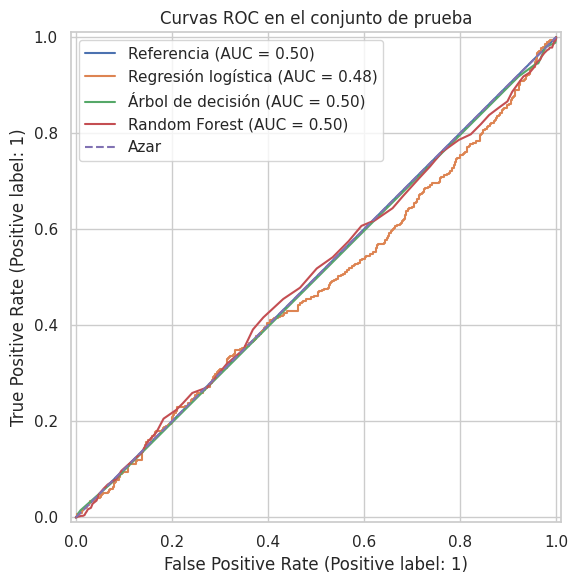

In [15]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, pipe in pipelines.items():
    if hasattr(pipe, "predict_proba"):
        RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", label="Azar")
ax.set_title("Curvas ROC en el conjunto de prueba")
ax.legend()
plt.tight_layout()
plt.show()

## 10. Validación cruzada estratificada de cinco pliegues

La validación cruzada se realiza solo sobre el conjunto de entrenamiento. Las métricas se presentan como media y desviación estándar.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_rows = []
for name, pipe in pipelines.items():
    scores = cross_validate(
        pipe, X_train, y_train, cv=cv, scoring=scoring,
        n_jobs=-1, error_score="raise"
    )
    row = {"Modelo": name}
    for metric in scoring:
        row[f"{metric} media"] = scores[f"test_{metric}"].mean()
        row[f"{metric} desviación"] = scores[f"test_{metric}"].std()
    cv_rows.append(row)

cv_df = pd.DataFrame(cv_rows).set_index("Modelo").round(3)
display(cv_df)

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

,accuracy media,accuracy desviación,precision media,precision desviación,recall media,recall desviación,f1 media,f1 desviación,roc_auc media,roc_auc desviación
Modelo,,,,,,,,,,
Referencia,0.502,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.500,0.000
Regresión logística,0.492,0.011,0.490,0.011,0.468,0.024,0.478,0.015,0.498,0.014
Árbol de decisión,0.500,0.012,0.491,0.015,0.551,0.323,0.471,0.175,0.503,0.013
Random Forest,0.498,0.014,0.496,0.014,0.476,0.032,0.485,0.023,0.503,0.016


## 11. Importancia de variables (exploratoria)

La importancia de Random Forest puede sesgarse hacia variables con más valores posibles y no implica causalidad. Solo debe interpretarse si el modelo muestra un rendimiento útil en validación.

,variable,importancia
8,num__bmi,0.100592
9,num__diabetes_pedigree,0.098437
2,num__cholesterol,0.093901
3,num__max_heart_rate,0.093450
5,num__plasma_glucose,0.092956
1,num__blood_pressure,0.089059
7,num__insulin,0.088180
0,num__age,0.087956
6,num__skin_thickness,0.087726
4,num__exercise_angina,0.016365


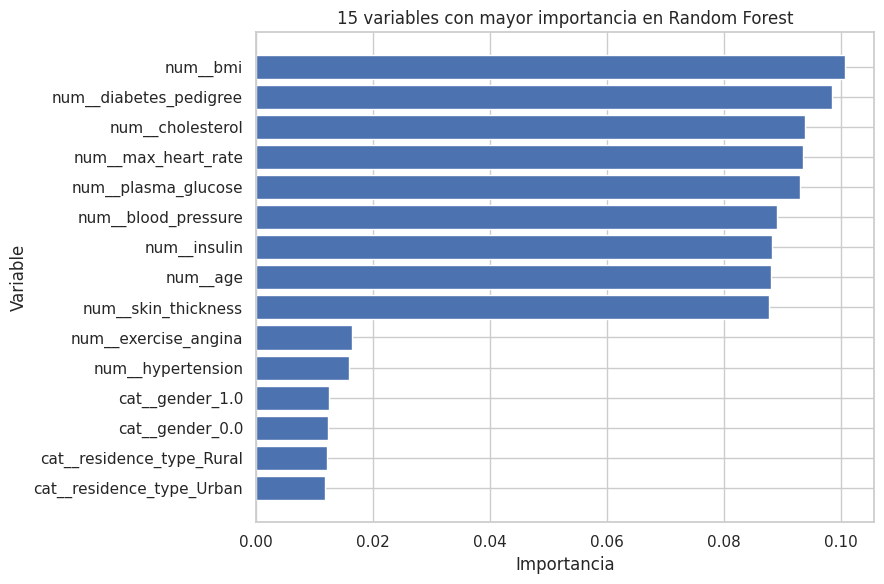

In [17]:
rf_pipe = pipelines["Random Forest"]
feature_names = rf_pipe.named_steps["preprocessor"].get_feature_names_out()
importances = rf_pipe.named_steps["model"].feature_importances_

importance_df = pd.DataFrame({
    "variable": feature_names,
    "importancia": importances
}).sort_values("importancia", ascending=False)

display(importance_df.head(20))

plt.figure(figsize=(9, 6))
plt.barh(importance_df.head(15)["variable"][::-1], importance_df.head(15)["importancia"][::-1])
plt.title("15 variables con mayor importancia en Random Forest")
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

## 12. Conclusiones automáticas de apoyo

Este resumen se genera a partir de las métricas calculadas. Revisa las tablas y formula las conclusiones finales con criterio académico; no se deben interpretar como evidencia clínica.

In [18]:
if "AUC-ROC" in results_df.columns:
    valid_auc = results_df["AUC-ROC"].dropna()
    if len(valid_auc):
        best_model = valid_auc.idxmax()
        best_auc = valid_auc.max()
        print(f"Mayor AUC en prueba: {best_model} ({best_auc:.3f}).")
        if abs(best_auc - 0.5) < 0.05:
            print("Interpretación orientativa: el AUC más alto está cerca de 0.5; no hay evidencia clara de discriminación útil.")
        elif best_auc > 0.5:
            print("El AUC más alto supera 0.5 en esta partición, pero debe revisarse junto con validación cruzada e incertidumbre.")
    else:
        print("No se pudo calcular AUC para los modelos evaluados.")
print("\nTamaño del dataset:", df.shape)
print("Variables predictoras:", X.shape[1])
print("Proporción positiva total:", round(y.mean(), 3))

Mayor AUC en prueba: Referencia (0.500).
Interpretación orientativa: el AUC más alto está cerca de 0.5; no hay evidencia clara de discriminación útil.

Tamaño del dataset: (6000, 16)
Variables predictoras: 15
Proporción positiva total: 0.498


# Tercer corte — Revisión de calidad, optimización y despliegue

Esta sección se añade al notebook del segundo corte. Los resultados del segundo corte (AUC ≈ 0,50 en todos los modelos) están por debajo del umbral de 0,70, por lo que se aplica la *Ficha técnica de revisión de calidad del modelado* antes de integrar el modelo en Streamlit.

## 13. Diagnóstico: ¿hay señal predictiva en los datos?

Se revisan la relación de cada variable con el objetivo (correlación e información mutua), la tasa de enfermedad por categoría y una prueba de permutaciones que compara el AUC real con el de etiquetas barajadas. También se revisa la forma de las distribuciones. Si el AUC real no se distingue del de las etiquetas permutadas, los datos no contienen información útil para el modelo, y ningún ajuste de hiperparámetros puede corregirlo.

In [ ]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import permutation_test_score

num_df = X_train[numeric_cols].apply(lambda s: s.fillna(s.median()))
corr = num_df.corrwith(y_train).abs()
mi = pd.Series(mutual_info_classif(num_df, y_train, random_state=RANDOM_STATE),
               index=numeric_cols)
display(pd.DataFrame({"|correlación con objetivo|": corr, "información mutua": mi})
        .sort_values("información mutua", ascending=False).round(4))

# ¿Alguna categoría cambia la tasa de enfermedad?
for c in categorical_cols:
    print(f"\nTasa de heart_disease=1 por {c}")
    display(pd.crosstab(X_train[c], y_train, normalize="index").round(3))

# Prueba de permutaciones: ¿el modelo rinde mejor que el azar?
score, perm_scores, pvalue = permutation_test_score(
    pipelines["Random Forest"], X_train, y_train, scoring="roc_auc",
    cv=cv, n_permutations=30, random_state=RANDOM_STATE, n_jobs=-1)
print(f"\nAUC real: {score:.3f} | AUC con etiquetas permutadas: {perm_scores.mean():.3f} "
      f"| p-valor: {pvalue:.3f}")

# Forma de las distribuciones (¿uniformes / sintéticas?)
display(df[numeric_cols].describe().T[["min", "mean", "std", "max"]].round(2))

**Lectura del diagnóstico:** ninguna variable numérica supera |r| = 0,02 con `heart_disease` y la información mutua máxima es 0,017 (insulina). Las tasas de enfermedad por categoría están entre 48 % y 52 %. La prueba de permutaciones da un AUC real de 0,503 frente a 0,497 con etiquetas barajadas (p = 0,32): el modelo no distingue la etiqueta real de una aleatoria. Además, las variables están acotadas por límites redondos (edad 18–90, colesterol 120–300, IMC 10–50, etc.) con distribuciones casi uniformes. Todo es compatible con un conjunto de datos sintético sin relación entre predictores y etiqueta; por tanto, ningún ajuste de hiperparámetros puede producir un modelo útil.

## 14. Optimización de hiperparámetros y comparación antes/después

Se ajustan regresión logística, Random Forest y Gradient Boosting con `GridSearchCV` (AUC-ROC, 5 pliegues estratificados) usando **solo el conjunto de entrenamiento**; el conjunto de prueba se usa una única vez para reportar. Se compara con los resultados del segundo corte.

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier

def make_pipe(model):
    return Pipeline([("preprocessor", clone(preprocessor)), ("model", model)])

candidatos = {
    "Regresión logística (ajustada)": (
        make_pipe(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
        {"model__C": [0.01, 0.1, 1, 10], "model__class_weight": [None, "balanced"]}),
    "Random Forest (ajustado)": (
        make_pipe(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
        {"model__n_estimators": [200, 400], "model__max_depth": [3, 5, 8, None],
         "model__min_samples_leaf": [1, 5, 20]}),
    "Gradient Boosting": (
        make_pipe(GradientBoostingClassifier(random_state=RANDOM_STATE)),
        {"model__learning_rate": [0.03, 0.1], "model__max_depth": [2, 3],
         "model__n_estimators": [100, 200]}),
}

ajustados, filas = {}, []
for nombre, (pipe, grid) in candidatos.items():
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)                       # solo datos de entrenamiento
    mejor = gs.best_estimator_
    ajustados[nombre] = mejor
    pred = mejor.predict(X_test)
    proba = mejor.predict_proba(X_test)[:, 1]
    filas.append({"Modelo": nombre, "Mejores parámetros": gs.best_params_,
                  "AUC CV": round(gs.best_score_, 3),
                  "Accuracy": accuracy_score(y_test, pred),
                  "Precision": precision_score(y_test, pred, zero_division=0),
                  "Recall": recall_score(y_test, pred, zero_division=0),
                  "F1": f1_score(y_test, pred, zero_division=0),
                  "AUC-ROC": roc_auc_score(y_test, proba)})

despues_df = pd.DataFrame(filas).set_index("Modelo").round(3)
print("ANTES (segundo corte):"); display(results_df)
print("DESPUÉS (optimización):"); display(despues_df)

**Conclusión de la optimización:** las diferencias entre modelos son del orden de la desviación entre pliegues (≈ 0,016 de AUC), por lo que no constituyen una mejora real. Se selecciona el **Random Forest ajustado** por tener el mayor AUC de validación cruzada y un recall de la clase positiva comparable al resto, sin pretender que el modelo tenga capacidad predictiva útil.

## 15. Exportación del pipeline para Streamlit

Se guarda el pipeline completo (preprocesamiento + modelo) con `joblib`, las métricas finales, una muestra de registros de prueba con la predicción del notebook (para verificar que la app coincide) y el archivo `requirements.txt` con las versiones utilizadas.

In [ ]:
import json, shutil, joblib, sklearn
from pathlib import Path

todos = {**pipelines, **ajustados}
FINAL_NAME = "Random Forest (ajustado)"   # modelo final elegido (ver justificación en el notebook)
final_pipe = todos[FINAL_NAME]

OUT = Path("streamlit_proyecto"); OUT.mkdir(exist_ok=True)
y_pred = final_pipe.predict(X_test)
y_proba = final_pipe.predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

cvs = cross_validate(final_pipe, X_train, y_train, cv=cv, n_jobs=-1,
                     scoring={"accuracy": "accuracy", "precision": "precision",
                              "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"})
metrics = {
    "modelo": FINAL_NAME,
    "test": {"accuracy": accuracy_score(y_test, y_pred),
             "precision": precision_score(y_test, y_pred, zero_division=0),
             "recall": recall_score(y_test, y_pred, zero_division=0),
             "f1": f1_score(y_test, y_pred, zero_division=0),
             "auc": roc_auc_score(y_test, y_proba)},
    "cv": {k: [float(cvs[f"test_{k}"].mean()), float(cvs[f"test_{k}"].std())]
           for k in ["accuracy", "precision", "recall", "f1", "roc_auc"]},
    "matriz_confusion": cm.tolist(),
}
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2))

joblib.dump(final_pipe, OUT / "pipeline_modelo.joblib", compress=3)

# Registros de prueba con la predicción del notebook (para comparar en la app)
muestra = X_test.head(30).copy()
muestra["heart_disease"] = y_test.head(30).values
muestra["pred_notebook"] = y_pred[:30]
muestra["proba_notebook"] = y_proba[:30].round(6)
muestra.to_csv(OUT / "muestra_prueba.csv", index=False)

shutil.copy(DATA_PATH, OUT / "patient_dataset.csv")
(OUT / "requirements.txt").write_text(
    "streamlit>=1.40\npandas>=2.2\nnumpy>=2.0\n"
    f"scikit-learn=={sklearn.__version__}\n"   # versión EXACTA: el .joblib depende de ella
    "joblib>=1.3\nmatplotlib>=3.8\n")
print("Archivos generados en", OUT.resolve())